![Banner](../../../../Images/Banner/07_remote_sensing/09_04_banner_rs_uav.png)


# UAV Fundamentals and Mission Planning

Ten notebooks follow a drone mission from the flight plan to measured crop traits.

- **UAV Fundamentals and Mission Planning.** This notebook. Altitude, camera, overlap and speed fix the pixel size, the number of images, and whether the frames can be turned into a map.
- **Reading and Inspecting UAV Imagery.** Read PNG and JPG frames into xarray, drop blurry or poorly exposed frames, and catalogue a multi-date folder.
- **Photogrammetry: Orthomosaic, DSM and DTM.** Turn overlapping frames into an orthomosaic, a DSM and a DTM with OpenDroneMap, and load the products with `rs.uav.load_outputs`.
- **RGB Vegetation Indices and Canopy Cover.** Compute VARI, TGI and Excess Green, mask vegetation, and track rice canopy cover over the LUMS dates.
- **RGB + NIR Multispectral Analysis.** Co-register a two-camera rig and follow NDVI on Canola, Drybean, Wheat and Lentil-Wheat.
- **DEM Correction and Canopy Height.** Remove the dome or bowl from a GCP-free DEM with RANSAC, then derive and check canopy height.
- **Plant Counting and Size.** Count rice hills from Excess Green peaks and from RiceNet density maps, tiled across large frames.
- **Crop Health: SAM Plant Masks and Senescence Detection.** Separate plant from background with SAM, then split green and senescent leaves.
- **Panicle Detection with YOLO.** Count panicles in sliding windows, merge overlaps with non-maximum suppression, and plug in YOLOv5 weights when they are available.
- **Season-Long Phenotyping.** Build one table of cover, greenness, yellowing, counts and height, then fit growth curves and stage dates.


## Overview

This notebook works through those flight choices with `rs.uav.flight_plan` and the camera presets in `rs.uav.CAMERAS`, then checks the numbers against a real mission. The LUMS rice phenotyping study (Chaudhry, Rana and Jaleel, 2026) flew a sub-250 g DJI Mini 4 Pro at 6 m for orthomosaics and 10 m for elevation models, recording 4K video instead of still photos.


## Core concepts

### Learning objectives

1. Compare UAV platforms and sensors (RGB, RGB + NIR, multispectral, thermal, lidar).
2. Compute ground sampling distance (GSD), image footprint, line spacing and trigger distance.
3. Plan video-based capture: frame spacing from speed, frame rate and frame step.
4. Size a mission: number of lines, images and flight time; grid vs multi-S patterns.
5. Account for sun angle, wind and regulations, and sanity-check GSD on a real frame.

### Data

| Data | Type |
|---|---|
| Flight plans from `rs.uav.flight_plan` and the camera presets in `rs.uav.CAMERAS` | **Calculated** |
| DJI Mini 4 Pro 4K frame, 3840 × 2160 px, rice, LUMS, 22 Aug 2025 (`Data/08_remote_sensing/08_04_uav/infrastructure-free-uav-phenotyping/2025-08-22`) | **Real** (CC BY 4.0) |

### Contents

1. Setup
2. Platforms and sensors
3. Ground sampling distance and footprint
4. Overlap, line spacing and trigger distance
5. Video-based capture
6. Sizing a mission and flight patterns
7. Sun angle, wind and regulations
8. Sanity-checking GSD on a real frame
9. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # control warning messages
warnings.filterwarnings("ignore")  # hide library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures

import geolattice.rsense as rs  # GeoLattice remote sensing (rs.uav = drone tools)

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_04_uav")  # data folder next to this notebook
LUMS = DATA / "infrastructure-free-uav-phenotyping"  # LUMS rice frames, one folder per date

## Platforms and sensors

The airframe sets endurance and area per flight; the sensor sets what can be measured.


In [2]:
platforms = pd.DataFrame([  # typical figures for agricultural mapping drones
    ("Sub-250 g multirotor (DJI Mini 4 Pro)", "25-34 min", "< 5 ha", "Light rules in many countries, RGB only"),
    ("Prosumer multirotor (Phantom 4, Mavic 3M)", "25-45 min", "5-30 ha", "Mechanical/large sensors, multispectral options"),
    ("Fixed-wing", "60-120 min", "100-1000 ha", "Efficient, needs landing space"),
    ("VTOL fixed-wing", "60-90 min", "100-700 ha", "Fixed-wing range, vertical take-off"),
], columns=["Platform", "Endurance", "Area per flight", "Notes"])
sensors = pd.DataFrame([
    ("Consumer RGB", "R, G, B", "0.2-3 cm", "Canopy cover, counting, 3-D structure (SfM)"),
    ("RGB + NIR rig (two cameras)", "R, G, B + NIR", "0.5-3 cm", "NDVI-type indices, needs co-registration"),
    ("Multispectral (RedEdge-MX, P4M, Mavic 3M)", "B, G, R, red edge, NIR", "3-8 cm", "Calibrated reflectance, nitrogen, vigour"),
    ("Thermal (radiometric LWIR)", "7.5-13.5 um", "5-15 cm", "Canopy temperature, water stress (CWSI)"),
    ("Lidar", "Return range", "points / m2", "Canopy height under vegetation, terrain"),
], columns=["Sensor", "Bands", "Typical GSD", "Typical use"])
display(platforms)  # show the platform table
display(sensors)  # show the sensor table

,Platform,Endurance,Area per flight,Notes
0,Sub-250 g multirotor (DJI Mini 4 Pro),25-34 min,< 5 ha,"Light rules in many countries, RGB only"
1,"Prosumer multirotor (Phantom 4, Mavic 3M)",25-45 min,5-30 ha,"Mechanical/large sensors, multispectral options"
2,Fixed-wing,60-120 min,100-1000 ha,"Efficient, needs landing space"
3,VTOL fixed-wing,60-90 min,100-700 ha,"Fixed-wing range, vertical take-off"


,Sensor,Bands,Typical GSD,Typical use
0,Consumer RGB,"R, G, B",0.2-3 cm,"Canopy cover, counting, 3-D structure (SfM)"
1,RGB + NIR rig (two cameras),"R, G, B + NIR",0.5-3 cm,"NDVI-type indices, needs co-registration"
2,"Multispectral (RedEdge-MX, P4M, Mavic 3M)","B, G, R, red edge, NIR",3-8 cm,"Calibrated reflectance, nitrogen, vigour"
3,Thermal (radiometric LWIR),7.5-13.5 um,5-15 cm,"Canopy temperature, water stress (CWSI)"
4,Lidar,Return range,points / m2,"Canopy height under vegetation, terrain"


## Ground sampling distance and footprint

For a nadir camera the size of one pixel on the ground is

$$GSD = \frac{\text{sensor width} \times \text{altitude}}{\text{focal length} \times \text{image width (px)}}$$

and the footprint is GSD times the image size. `rs.uav.CAMERAS` holds presets. The Mini 4 Pro
presets are built from the published 24 mm-equivalent focal length with
`rs.uav.camera_from_equivalent`, since DJI does not list the physical sensor width; only the
ratio of sensor width to focal length matters for GSD.


In [3]:
cams = pd.DataFrame([{"key": k, **vars(c)} for k, c in rs.uav.CAMERAS.items()])  # one row per preset
cams[["key", "name", "sensor_width_mm", "focal_mm", "image_width_px", "image_height_px"]].round(2)

,key,name,sensor_width_mm,focal_mm,image_width_px,image_height_px
0,phantom4pro,DJI Phantom 4 Pro,13.20,8.80,5472,3648
1,mavic3m_rgb,DJI Mavic 3M RGB,17.30,12.29,5280,3956
2,p4multispectral,DJI P4 Multispectral (each band),4.87,5.74,1600,1300
3,rededge_mx,MicaSense RedEdge-MX,4.80,5.40,1280,960
4,mini4pro,DJI Mini 4 Pro (48 MP photo),34.62,24.00,8064,6048
5,mini4pro_4k_video,DJI Mini 4 Pro (4K video frame),37.71,24.00,3840,2160


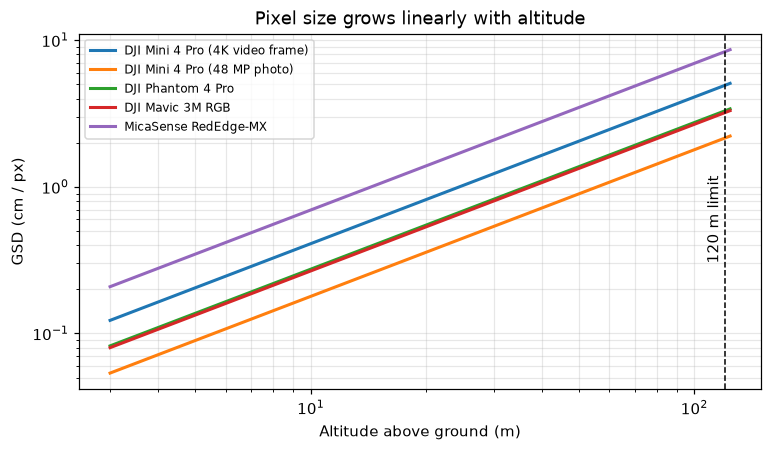

In [4]:
alt = np.arange(3, 125, 1.0)  # altitudes from 3 m to 124 m
fig, ax = plt.subplots(figsize=(8, 4.2))
for key in ["mini4pro_4k_video", "mini4pro", "phantom4pro", "mavic3m_rgb", "rededge_mx"]:
    gsd = [rs.uav.flight_plan(a, camera=key)["gsd_cm"] for a in alt]  # GSD at each altitude
    ax.plot(alt, gsd, lw=2, label=rs.uav.CAMERAS[key].name)
ax.axvline(120, color="k", ls="--", lw=1)  # common legal ceiling (about 400 ft)
ax.text(118, 0.3, "120 m limit", rotation=90, ha="right", va="bottom")
ax.set(xlabel="Altitude above ground (m)", ylabel="GSD (cm / px)", xscale="log", yscale="log",
       title="Pixel size grows linearly with altitude")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
plt.show()

## Overlap, line spacing and trigger distance

Photogrammetry needs every ground point in several images. Forward (front) overlap is set by
the distance between exposures along a line, side overlap by the spacing between lines:

* line spacing = footprint width × (1 - side overlap)
* trigger distance = footprint height × (1 - front overlap)

The LUMS paper flew two missions per date: 6 m for orthomosaics and 10 m for DEMs.


In [5]:
rows = []
for altitude, purpose in [(6, "orthomosaic"), (10, "DEM")]:
    p = rs.uav.flight_plan(altitude, camera="mini4pro_4k_video", front_overlap=0.8, side_overlap=0.7)
    rows.append({"mission": purpose, "altitude_m": altitude, **{k: round(v, 3) for k, v in p.items()}})
lums_plan = pd.DataFrame(rows).set_index("mission")
lums_plan

,altitude_m,gsd_cm,footprint_w_m,footprint_h_m,line_spacing_m,trigger_distance_m
mission,,,,,,
orthomosaic,6,0.246,9.428,5.303,2.828,1.061
DEM,10,0.409,15.714,8.839,4.714,1.768


The nominal GSD from the preset (about 2.5 mm at 6 m) is larger than the 1.85 mm/px the LUMS
authors report for their 6 m orthomosaics. Two things can explain it: DJI video modes crop
and rescale the sensor, so the effective field of view differs from the photo field of view,
and SfM software reports the GSD of its own output grid, which can be finer than one frame.
The lesson is general: **treat preset GSD as a planning figure and confirm it from the data**
(Section 8) or from the photogrammetry report.


## Video-based capture

LUMS recorded 4K video at 24 frames per second, flying at about 1 m/s, and kept every 6th
frame. The distance between kept frames is

$$\text{frame spacing} = \frac{\text{speed} \times \text{frame step}}{\text{fps}} = \frac{1 \times 6}{24} = 0.25\ \text{m}$$

Pass `speed_ms`, `fps` and `frame_step` to `flight_plan` to get the spacing and the forward
overlap it implies.


In [6]:
video = []
for step in [1, 3, 6, 12, 24, 48]:
    p = rs.uav.flight_plan(6, camera="mini4pro_4k_video", speed_ms=1.0, fps=24, frame_step=step)
    video.append({"frame_step": step, "frame_spacing_m": p["frame_spacing_m"],
                  "front_overlap_%": 100 * p["video_front_overlap"],
                  "frames_per_30m_line": int(np.ceil(30 / p["frame_spacing_m"])) + 1})
pd.DataFrame(video).round(3)

,frame_step,frame_spacing_m,front_overlap_%,frames_per_30m_line
0,1,0.042,99.214,721
1,3,0.125,97.643,241
2,6,0.250,95.286,121
3,12,0.500,90.572,61
4,24,1.000,81.144,31
5,48,2.000,62.288,16


With a 5.3 m along-track footprint at 6 m, every 6th frame still overlaps by about 95 %.
That is far more than SfM needs (75 to 85 %) but keeps motion-blurred frames replaceable:
`rs.uav.extract_frames(video, out, step=6, min_blur=...)` drops blurred frames while
extracting (notebook 09_04_02).


## Sizing a mission and flight patterns

The LUMS field has two 30 m × 10 m plots. The helper below counts lines, images and flight
time for a rectangular block flown in parallel lines.


In [7]:
def mission(width_m, length_m, altitude, camera, *, front=0.8, side=0.7, speed=1.0,
            fps=None, frame_step=1, turn_s=8.0):
    """Lines, images and minutes for a block of parallel lines along the long side."""
    p = rs.uav.flight_plan(altitude, camera=camera, front_overlap=front, side_overlap=side,
                           speed_ms=speed, fps=fps, frame_step=frame_step)
    n_lines = int(np.ceil(width_m / p["line_spacing_m"])) + 1  # cover the block edge to edge
    step = p.get("frame_spacing_m", p["trigger_distance_m"])  # video frame or photo trigger spacing
    per_line = int(np.ceil(length_m / step)) + 1
    seconds = n_lines * length_m / speed + (n_lines - 1) * (p["line_spacing_m"] / speed + turn_s)
    return {"altitude_m": altitude, "gsd_mm": 10 * p["gsd_cm"], "lines": n_lines,
            "line_spacing_m": p["line_spacing_m"], "images": n_lines * per_line, "minutes": seconds / 60}

table = pd.DataFrame([
    mission(20, 30, 6, "mini4pro_4k_video", fps=24, frame_step=6),
    mission(20, 30, 10, "mini4pro_4k_video", fps=24, frame_step=6),
    mission(20, 30, 10, "mini4pro_4k_video", speed=2.0, fps=24, frame_step=12),
    mission(20, 30, 30, "mini4pro", speed=3.0),
], index=["LUMS ortho, 6 m", "LUMS DEM, 10 m", "10 m, 2 m/s", "30 m photos"])
table.round(2)

,altitude_m,gsd_mm,lines,line_spacing_m,images,minutes
"LUMS ortho, 6 m",6,2.46,9,2.83,1089,5.94
"LUMS DEM, 10 m",10,4.09,6,4.71,726,4.06
"10 m, 2 m/s",10,4.09,6,4.71,186,2.36
30 m photos,30,5.37,3,12.98,18,0.91


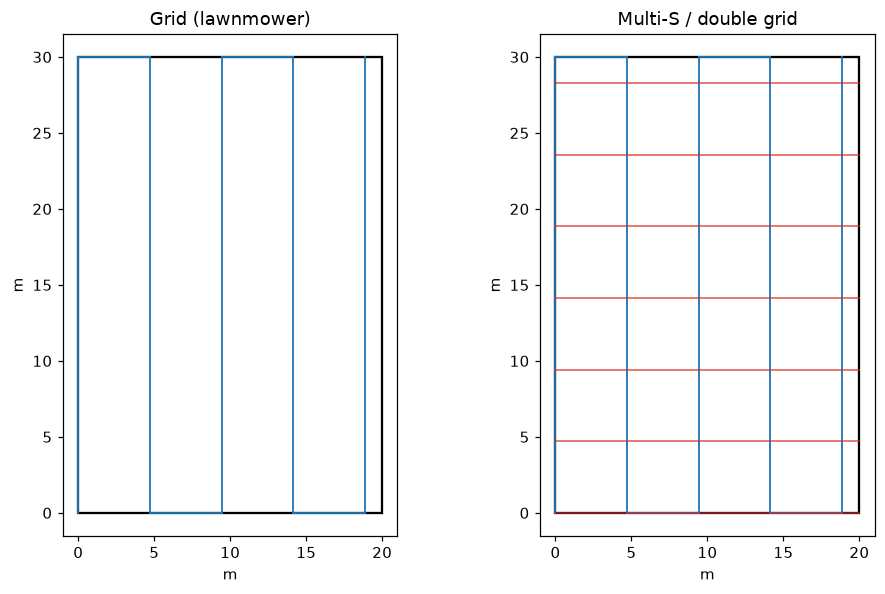

In [8]:
def draw_pattern(ax, width, length, spacing, multi_s=False):
    """Draw a grid (parallel lines, lawnmower) or a multi-S (cross-hatched) pattern."""
    xs = np.arange(0, width + spacing / 2, spacing)
    for i, x in enumerate(xs):  # serpentine along y
        ys = [0, length] if i % 2 == 0 else [length, 0]
        ax.plot([x, x], ys, color="C0", lw=1.2)
        if i < len(xs) - 1:
            ax.plot([x, xs[i + 1]], [ys[1], ys[1]], color="C0", lw=1.2)
    if multi_s:  # a second pass perpendicular to the first
        ys2 = np.arange(0, length + spacing / 2, spacing)
        for j, y in enumerate(ys2):
            xx = [0, width] if j % 2 == 0 else [width, 0]
            ax.plot(xx, [y, y], color="C3", lw=1.0, alpha=0.8)
    ax.add_patch(plt.Rectangle((0, 0), width, length, fill=False, color="k", lw=1.5))
    ax.set(aspect="equal", xlabel="m", ylabel="m")

sp = rs.uav.flight_plan(10, camera="mini4pro_4k_video", side_overlap=0.7)["line_spacing_m"]
fig, axes = plt.subplots(1, 2, figsize=(9, 5.5))
draw_pattern(axes[0], 20, 30, sp); axes[0].set_title("Grid (lawnmower)")
draw_pattern(axes[1], 20, 30, sp, multi_s=True); axes[1].set_title("Multi-S / double grid")
plt.tight_layout(); plt.show()

A single grid is enough for orthomosaics over flat fields. A double grid (multi-S, flown again
at 90°) adds viewing angles that stabilise SfM camera calibration and reduce the doming that
appears in elevation models built without ground control (notebook 09_04_06). It roughly
doubles flight time.


## Sun angle, wind and regulations

**Sun.** Low sun casts long shadows that hide soil and inflate apparent canopy cover; very
high sun over water and wet soil (as in flooded rice) gives specular glare. A common rule is
to fly within about two hours of solar noon, or under uniform overcast. The function below
gives solar elevation from date, time and latitude (NOAA approximation, accurate to well under
a degree).


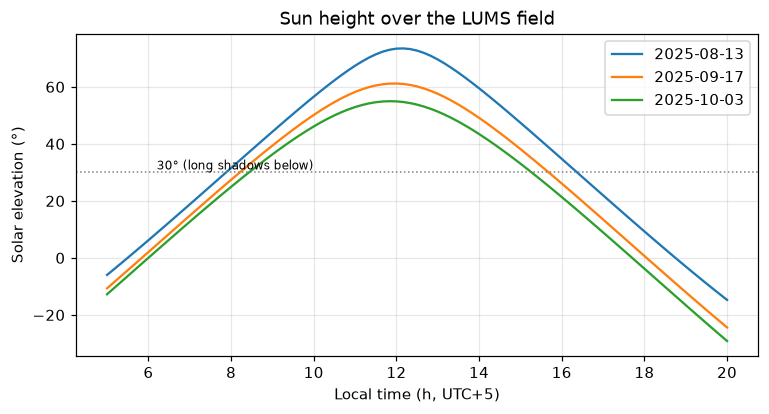

In [9]:
def solar_elevation(when, lat, lon):
    """Solar elevation angle (degrees) for UTC timestamps at a latitude/longitude."""
    t = pd.to_datetime(when)
    doy = t.dayofyear.to_numpy() if hasattr(t, "dayofyear") else t.dayofyear
    hour = t.hour + t.minute / 60
    g = 2 * np.pi / 365 * (doy - 1 + (hour - 12) / 24)  # fractional year (radians)
    decl = (0.006918 - 0.399912 * np.cos(g) + 0.070257 * np.sin(g) - 0.006758 * np.cos(2 * g)
            + 0.000907 * np.sin(2 * g) - 0.002697 * np.cos(3 * g) + 0.00148 * np.sin(3 * g))
    eqt = 229.18 * (0.000075 + 0.001868 * np.cos(g) - 0.032077 * np.sin(g)
                    - 0.014615 * np.cos(2 * g) - 0.040849 * np.sin(2 * g))  # minutes
    solar_time = hour * 60 + eqt + 4 * lon  # true solar time in minutes
    ha = np.radians(solar_time / 4 - 180)  # hour angle
    phi = np.radians(lat)
    cos_z = np.sin(phi) * np.sin(decl) + np.cos(phi) * np.cos(decl) * np.cos(ha)
    return 90 - np.degrees(np.arccos(np.clip(cos_z, -1, 1)))

lat, lon = 31.47, 74.41  # Lahore (LUMS campus), Pakistan, UTC+5
fig, ax = plt.subplots(figsize=(8, 3.8))
for day in ["2025-08-13", "2025-09-17", "2025-10-03"]:
    utc = pd.date_range(f"{day} 00:00", f"{day} 15:00", freq="10min")  # 05:00-20:00 local
    ax.plot(utc.hour + utc.minute / 60 + 5, solar_elevation(utc, lat, lon), label=day)
ax.axhline(30, color="grey", ls=":", lw=1); ax.text(6.2, 31, "30° (long shadows below)", fontsize=8)
ax.set(xlabel="Local time (h, UTC+5)", ylabel="Solar elevation (°)", title="Sun height over the LUMS field")
ax.legend(); ax.grid(alpha=0.3); plt.show()

**Wind.** Sub-250 g drones drift and tilt in gusts, which blurs frames and changes the view
angle; keep sustained wind under about half the aircraft's rated limit for mapping work,
and fly lines across the wind where possible so ground speed stays constant.

**Regulations.** Rules differ by country and change often. In many jurisdictions drones under
250 g face lighter registration requirements, but altitude limits (commonly 120 m above
ground), visual line of sight, distance from people and airports, and data-protection rules
still apply. Always check the current rules of your aviation authority and get landowner
permission before flying.


## Sanity-checking GSD on a real frame

A frame's GSD can be checked against any object of known size. Rice in the LUMS field was
transplanted in rows; at the reported 1.85 mm/px a 3840 × 2160 frame covers about
7.1 m × 4.0 m. Below, one frame is read with that GSD so the axes are in metres, and a 1 m
scale bar is drawn. Compare the bar with the plant spacing you expect (about 0.2 m between
hills in transplanted rice) to judge whether the stated GSD is plausible.


Frozen({'band': 3, 'y': 2160, 'x': 3840}) | footprint: 7.1 m x 4.0 m


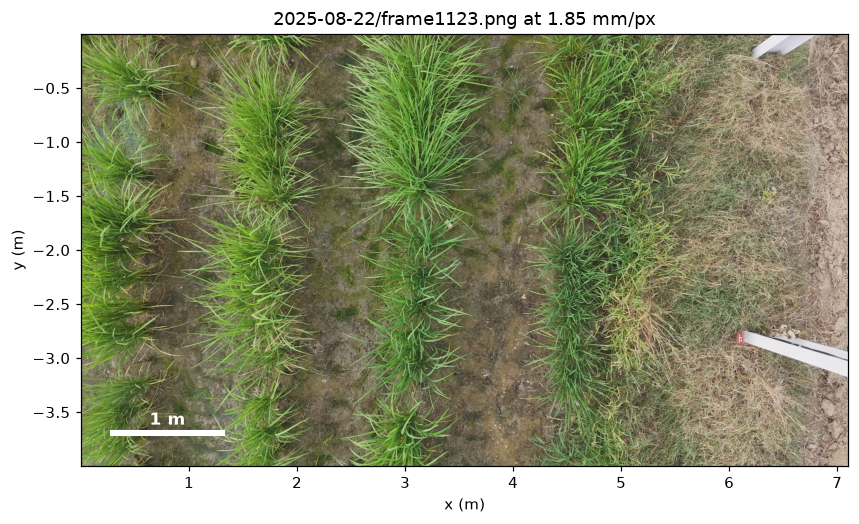

In [10]:
frame_path = sorted((LUMS / "2025-08-22").glob("*.png"))[0]  # first sample frame of 22 Aug
gsd_m = 0.00185  # 1.85 mm/px reported for the 6 m orthomosaics
img = rs.uav.read_frame(frame_path, gsd=gsd_m)  # (band, y, x) in metres
print(img.sizes, "| footprint:", round(img.sizes["x"] * gsd_m, 2), "m x", round(img.sizes["y"] * gsd_m, 2), "m")

fig, ax = plt.subplots(figsize=(9, 5.2))
ext = [float(img.x.min()), float(img.x.max()), float(img.y.min()), float(img.y.max())]
ax.imshow(rs.uav.to_rgb_array(img), extent=ext)
x0, y0 = ext[0] + 0.3, ext[2] + 0.3
ax.plot([x0, x0 + 1.0], [y0, y0], color="white", lw=4)  # 1 m scale bar
ax.text(x0 + 0.5, y0 + 0.08, "1 m", color="white", ha="center", fontsize=11, weight="bold")
ax.set(xlabel="x (m)", ylabel="y (m)", title=f"{frame_path.parent.name}/{frame_path.name} at 1.85 mm/px")
plt.show()

## Summary and exercises

**Key points**

- GSD = sensor width × altitude / (focal length × image width). Treat a camera preset as a
  planning figure and confirm it on a real frame or in the photogrammetry report.
- Line spacing and trigger distance follow from the footprint and the overlap. SfM needs on
  the order of 75 to 85% forward overlap; the LUMS video still overlaps by about 95% at 6 m.
- For video, frame spacing = speed × frame step / fps. At 1 m/s and 24 fps, every 6th frame
  is 0.25 m apart.
- A second grid at 90° costs about twice the flight time and gives the extra view angles
  that reduce doming when there is no ground control.
- Fly within about two hours of solar noon, keep the wind well under the aircraft's mapping
  limit, and check the current airspace rules before take-off.

**GeoLattice functions used:** `rs.uav.flight_plan`, `rs.uav.CAMERAS`, `rs.uav.read_frame`.

**Exercises**

1. A MicaSense RedEdge-MX must deliver 5 cm GSD. At what altitude must it fly, and how many
   lines does a 200 m × 150 m field need at 75 % side overlap?
2. Using `mission()`, find the fastest speed at which the LUMS 10 m DEM mission keeps at least
   85 % forward overlap when every 12th video frame is kept.
3. Extend `solar_elevation` to report the time window when the sun is above 45° on
   2025-09-17 at the LUMS field.
4. Pick another frame from a later date. Do plant spacing and the 1 m bar still agree? What
   would a 10 m flight do to the bar's length in pixels?

**References**

- Chaudhry, H., Rana, S. and Jaleel, A. (2026). UAV-based crop reconstruction and trait
  estimation using RGB imagery without external geospatial infrastructure. *Computers and
  Electronics in Agriculture* (accepted). Data: CC BY 4.0; code: MIT.
- NOAA Global Monitoring Laboratory. General solar position calculations.
- James, M. R. and Robson, S. (2014). Mitigating systematic error in topographic models derived
  from UAV and ground-based image networks. *Earth Surface Processes and Landforms*, 39, 1413-1420.
